In [ ]:
# NBA Game Total Points Regression

This notebook predicts the combined points scored by both teams using only team statistics available before tipoff.

## Project Objective

Predict a game's **total points** (`pts_home + pts_away`) before the game begins.

**Target:** `total_points`  
**Unit:** combined points for both teams  
**Features:** only five-game prior-team statistics constructed in the preprocessing notebook  
**Validation:** chronological train/test split, so the model is always tested on games newer than all training games

## Imports and Configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Load Prepared Dataset

The preprocessed dataset contains five-game prior averages for the home and away teams. Team points and the final score from the current game are used only to create the target and are excluded from the predictors.

In [2]:
data_dir = Path("data") if Path("data").is_dir() else Path("../data")

df = pd.read_csv(data_dir / "processed_games.csv", parse_dates=["game_date"])
df = df.sort_values(["game_date", "game_id"]).reset_index(drop=True)

df["total_points"] = df["pts_home"] + df["pts_away"]

feature_cols = [column for column in df.columns if column.endswith("_last5")]
X = df[feature_cols]
y = df["total_points"]

print(f"Prepared games: {len(df):,}")
print(f"Predictor features: {len(feature_cols)}")
print(f"Date range: {df['game_date'].min().date()} through {df['game_date'].max().date()}")
print(f"Total-points range: {y.min():.0f} to {y.max():.0f}")
display(df[["game_date", "season_id", "pts_home", "pts_away", "total_points"]].head())

Prepared games: 11,086
Predictor features: 22
Date range: 2010-11-05 through 2023-04-09
Total-points range: 141 to 329


,game_date,season_id,pts_home,pts_away,total_points
0,2010-11-05,22010,103.0,113.0,216.0
1,2010-11-06,22010,81.0,87.0,168.0
2,2010-11-06,22010,91.0,100.0,191.0
3,2010-11-07,22010,96.0,106.0,202.0
4,2010-11-07,22010,114.0,118.0,232.0


## Chronological Train/Test Split

Random splits would allow future games to influence a model before predicting past games. This split is instead ordered by game date.

- Training: earliest 80% of games
- Testing: newest 20% of games
- No current-game point totals or win outcome are included in `X`

In [4]:
unique_dates = np.array(sorted(df["game_date"].unique()))
date_split_index = int(len(unique_dates) * 0.80)
split_date = unique_dates[date_split_index]

train = df[df["game_date"] < split_date].copy()
test = df[df["game_date"] >= split_date].copy()

X_train = train[feature_cols]
y_train = train["total_points"]
X_test = test[feature_cols]
y_test = test["total_points"]

assert train["game_date"].max() < test["game_date"].min()
assert not set(feature_cols).intersection({"pts_home", "pts_away", "total_points", "home_win", "point_differential"})

print("Cutoff date:", pd.Timestamp(split_date).date())
print("Training window:", train["game_date"].min().date(), "to", train["game_date"].max().date())
print("Testing window:", test["game_date"].min().date(), "to", test["game_date"].max().date())
print("Training games:", len(train))
print("Testing games:", len(test))

Cutoff date: 2021-04-04
Training window: 2010-11-05 to 2021-04-03
Testing window: 2021-04-04 to 2023-04-09
Training games: 8864
Testing games: 2222


## Models

We compare a simple mean baseline, ordinary linear regression, Ridge regression, Random Forest, and Gradient Boosting.

- **Mean baseline:** predicts the training-set average total for every game.
- **Linear/Ridge:** capture mostly additive relationships between rolling team averages.
- **Random Forest:** captures nonlinear interactions.
- **Gradient Boosting:** learns residual patterns with shallow trees.

In [5]:
models = {
    "Mean baseline": None,
    "Linear regression": LinearRegression(),
    "Ridge regression": Ridge(alpha=10.0),
    "Random forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        loss="huber",
        random_state=RANDOM_STATE,
    ),
}

predictions = {}
training_mean = y_train.mean()

for name, model in models.items():
    if model is None:
        predictions[name] = np.full(len(X_test), training_mean)
    else:
        model.fit(X_train, y_train)
        predictions[name] = model.predict(X_test)

results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R2": r2_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
results_df.round(3)

,Model,MAE,RMSE,R2
0,Ridge regression,14.919,18.948,0.093
1,Linear regression,14.919,18.947,0.093
2,Gradient boosting,15.053,19.155,0.073
3,Random forest,15.083,19.228,0.066
4,Mean baseline,21.072,26.153,-0.729


## Model Comparison

MAE is the primary metric because it reports the average absolute error in points. RMSE is included because it penalizes large misses more heavily, while R² measures how much held-out variance the model explains.

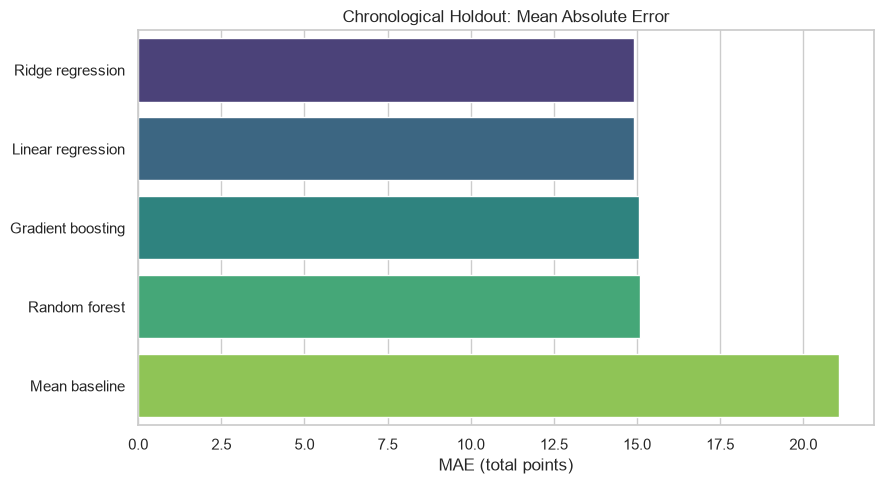

Best model by MAE: Ridge regression


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=results_df, x="MAE", y="Model", hue="Model", palette="viridis", legend=False, ax=ax)
ax.set_title("Chronological Holdout: Mean Absolute Error")
ax.set_xlabel("MAE (total points)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]
print(f"Best model by MAE: {best_model_name}")

## Predicted vs. Actual Total Points

For a perfect model, points would fall on the diagonal. The wider the vertical spread around that line, the larger the average prediction uncertainty.

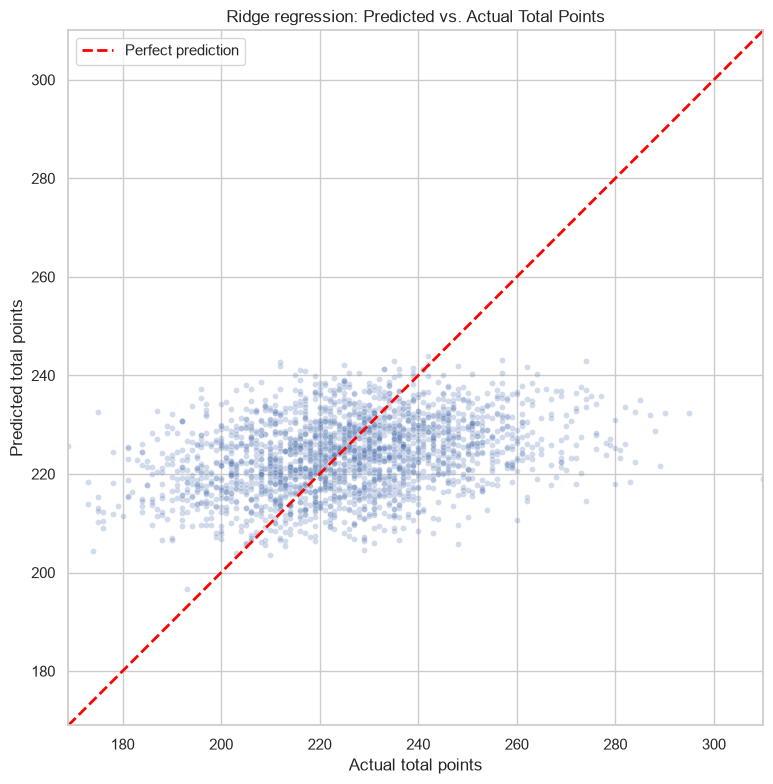

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.25, s=18, ax=ax)
limits = [min(y_test.min(), best_predictions.min()), max(y_test.max(), best_predictions.max())]
ax.plot(limits, limits, "--", color="red", linewidth=2, label="Perfect prediction")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal", adjustable="box")
ax.set_title(f"{best_model_name}: Predicted vs. Actual Total Points")
ax.set_xlabel("Actual total points")
ax.set_ylabel("Predicted total points")
ax.legend()
plt.tight_layout()
plt.show()

## Residual Analysis

Residuals are calculated as `actual - predicted`. A well-behaved model should have residuals centered near zero with no strong dependence on the predicted value.

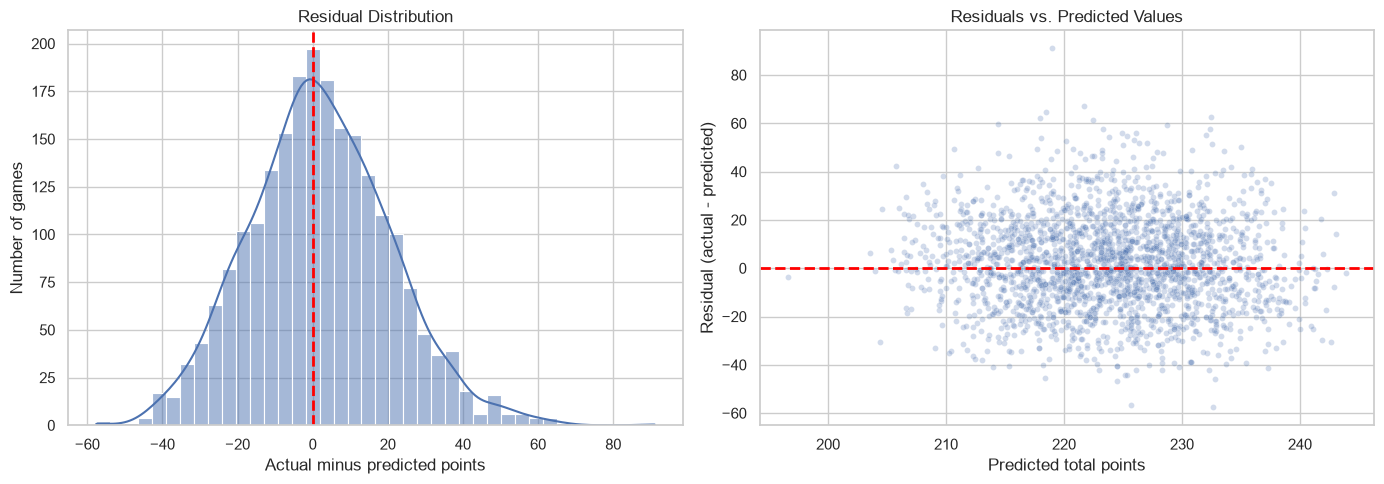

Residual mean: 2.022
Residual standard deviation: 18.844


In [8]:
residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals, bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(0, color="red", linestyle="--", linewidth=2)
axes[0].set_title("Residual Distribution")
axes[0].set_xlabel("Actual minus predicted points")
axes[0].set_ylabel("Number of games")

sns.scatterplot(x=best_predictions, y=residuals, alpha=0.25, s=18, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted total points")
axes[1].set_ylabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()

print("Residual mean:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

## Feature Interpretation

Permutation importance measures how much MAE worsens when one feature is shuffled. Larger values indicate stronger usefulness for the Ridge model; these rankings describe predictive association, not causation.

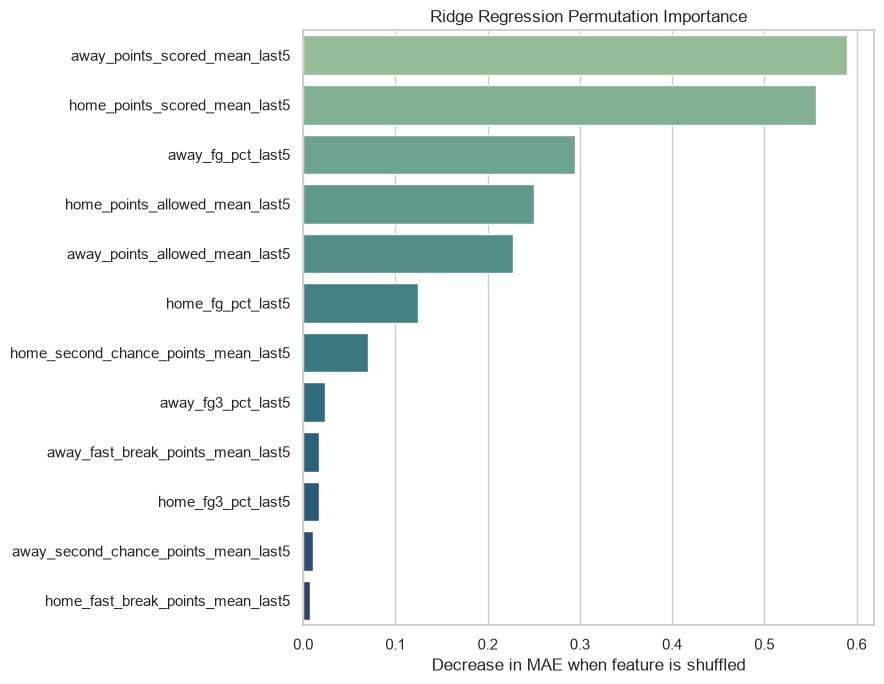

,Feature,Importance
12,away_points_scored_mean_last5,0.58948
1,home_points_scored_mean_last5,0.55577
20,away_fg_pct_last5,0.29486
2,home_points_allowed_mean_last5,0.25012
13,away_points_allowed_mean_last5,0.22794
9,home_fg_pct_last5,0.12476
6,home_second_chance_points_mean_last5,0.07003
21,away_fg3_pct_last5,0.02410
18,away_fast_break_points_mean_last5,0.01753
10,home_fg3_pct_last5,0.01700


In [9]:
ridge_model = models["Ridge regression"]
perm = permutation_importance(
    ridge_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
)

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": perm.importances_mean,
}).sort_values("Importance", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=importance_df.head(12), x="Importance", y="Feature", hue="Feature", palette="crest", legend=False, ax=ax)
ax.set_title("Ridge Regression Permutation Importance")
ax.set_xlabel("Decrease in MAE when feature is shuffled")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(importance_df.head(12).round(5))

## Results and Next Steps

- Ridge and ordinary linear regression were the strongest of the tested models on the latest chronological holdout.
- The mean baseline was substantially worse, so recent team statistics contain useful pre-game information.
- Ridge achieved an MAE of about 14.9 points, meaning its predictions differed from actual combined totals by roughly 15 points on average.
- The held-out R² was only about 0.09, showing that game-to-game scoring variance is difficult to predict from these five-game averages alone.

Possible future improvements include adding season-phase trends, days of rest, back-to-back status, starting-lineup information, and opponent-adjusted scoring rates.

In [10]:
results_path = data_dir / "total_points_model_results.csv"
results_df.round(6).to_csv(results_path, index=False)
print(f"Saved model comparison to {results_path}")

Saved model comparison to ../data/total_points_model_results.csv
